In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [10]:
df = pd.read_csv("chd-201015-202131.csv")

df.head()

,Obs,ID,AGE,agrp,CHD
0,1,1,20,1,0
1,2,2,23,1,0
2,3,3,24,1,0
3,4,4,25,1,0
4,5,5,25,1,1


Explore dataset

In [11]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

print(df['CHD'].value_counts())

(100, 5)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Obs     100 non-null    int64
 1   ID      100 non-null    int64
 2   AGE     100 non-null    int64
 3   agrp    100 non-null    int64
 4   CHD     100 non-null    int64
dtypes: int64(5)
memory usage: 4.0 KB
None
              Obs          ID         AGE        agrp        CHD
count  100.000000  100.000000  100.000000  100.000000  100.00000
mean    50.500000   50.500000   44.380000    4.480000    0.43000
std     29.011492   29.011492   11.721327    2.240491    0.49757
min      1.000000    1.000000   20.000000    1.000000    0.00000
25%     25.750000   25.750000   34.750000    2.750000    0.00000
50%     50.500000   50.500000   44.000000    4.000000    0.00000
75%     75.250000   75.250000   55.000000    7.000000    1.00000
max    100.000000  100.000000   69.000000    8.000000    1.00000
Obs     0
ID      0
AGE   

Handle missing values

In [12]:
df = df.dropna(subset=['AGE', 'CHD'])

print(df.isnull().sum())

Obs     0
ID      0
AGE     0
agrp    0
CHD     0
dtype: int64


Separate independent and dependent variables

In [13]:
X = df[['AGE']]

y = df['CHD']

Split dataset

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 1)
Testing data: (20, 1)


Create and train Logistic Regression model

In [15]:
model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Make predictions

In [16]:
y_pred = model.predict(X_test)

print(y_pred)

[0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0]


Evaluate model performance

In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.6
Precision: 0.6
Recall: 0.3333333333333333
F1 Score: 0.42857142857142855


Confusion matrix

In [18]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[9 2]
 [6 3]]


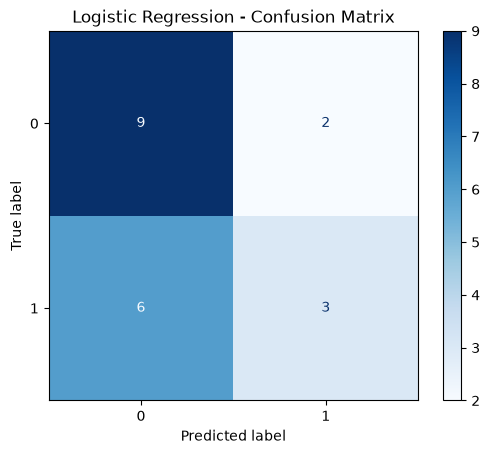

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Classification report

In [20]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.60      0.82      0.69        11
           1       0.60      0.33      0.43         9

    accuracy                           0.60        20
   macro avg       0.60      0.58      0.56        20
weighted avg       0.60      0.60      0.57        20



Visualize Logistic Regression

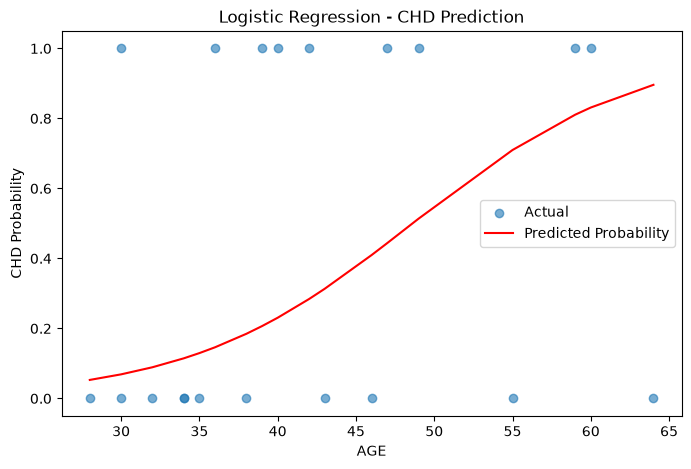

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test['AGE'],
    y_test,
    label='Actual',
    alpha=0.6
)

sorted_indices = np.argsort(X_test['AGE'].values)

plt.plot(
    X_test['AGE'].values[sorted_indices],
    model.predict_proba(X_test)[sorted_indices, 1],
    color='red',
    label='Predicted Probability'
)

plt.xlabel("AGE")
plt.ylabel("CHD Probability")
plt.title("Logistic Regression - CHD Prediction")

plt.legend()
plt.show()

Predict CHD for a new person

In [24]:
new_person = pd.DataFrame({
    'AGE': [55]
})

prediction = model.predict(new_person)

probability = model.predict_proba(new_person)

if prediction[0] == 1:
    print("Predicted class: CHD")
else:
    print("Predicted class: No CHD")

print("Probability of CHD:", probability[0][1])

Predicted class: CHD
Probability of CHD: 0.7098112030636834
